####  Tasks

- First, explore fitting this data with the tecniques we have seen.
- Start from linear regression and polynomial regression
- For the case of  polynomial regression, just fit many of them for now.
- Let's bet based on intuition! Which fit is the best?
- In what cases are you underfitting the data?
- In what cases are you overfitting the data?
- Now split the data into training and validation sets
- Implement a cross-validation procedure
- Pick the best!
- Does it agree with our bets?

<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
C:\Users\user\AppData\Local\Temp\ipykernel_20484\2268563166.py:9: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


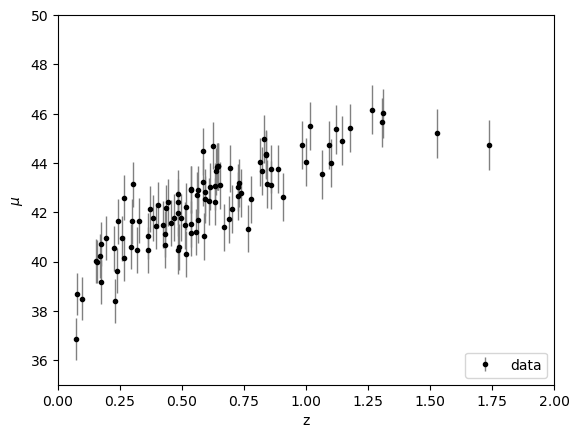

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from astroML.datasets import generate_mu_z
z_sample, mu_sample, dmu = generate_mu_z(100, random_state=1234) # YOU CANNOT CHANGE THIS

plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50);

Linear fit:  slope = 4.764,  intercept = 39.484


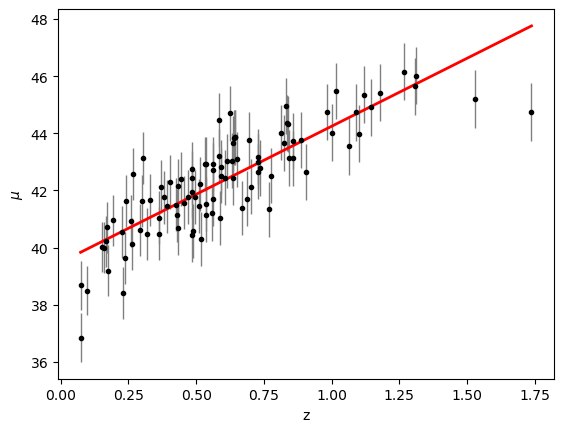

In [7]:
#start with linear regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import learning_curve

x = z_sample[:, np.newaxis]
y = mu_sample

model = LinearRegression()
weights = 1/dmu**2
model.fit(x, y, sample_weight=weights)

theta0 = model.intercept_
theta1 = model.coef_[0]
print(f'Linear fit:  slope = {theta1:.3f},  intercept = {theta0:.3f}')

x_fit = np.linspace(x.min(), x.max(), 300)
y_fit = theta1 * x_fit + theta0

plt.figure()
plt.errorbar(x, y, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.plot(x_fit, y_fit, 'r-', lw=2, label=f'Linear fit (d=1)')
plt.xlabel(r'z')
plt.ylabel(r'$\mu$')
plt.show()

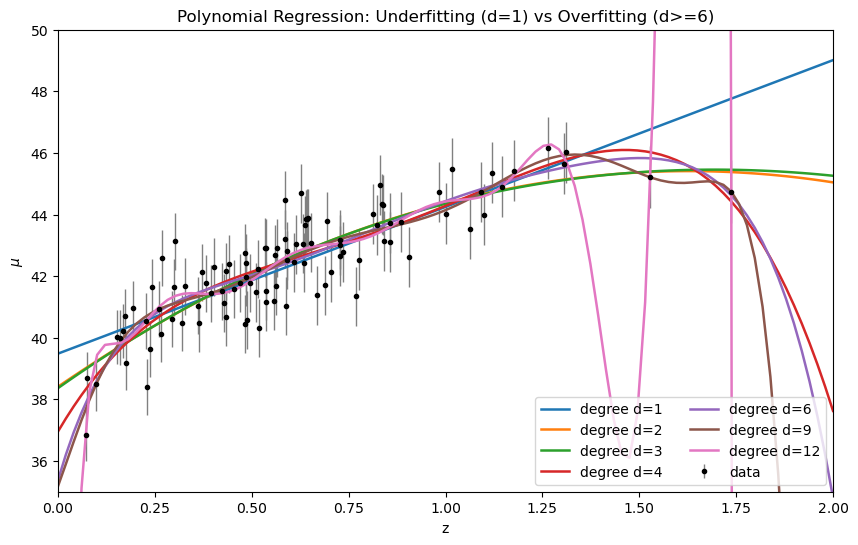

In [8]:
#now lets do the polynomial regression 

from astroML.linear_model import PolynomialRegression

z_grid = np.linspace(0, 2, 100)

plt.figure(figsize=(10, 6))
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1, label='data')

# Fittiamo polinomi di vari gradi per confrontare underfitting vs overfitting
degrees = [1, 2, 3, 4, 6, 9, 12]

for d in degrees:
    model = PolynomialRegression(d)
    # IMPORTANTE: passare dmu come terzo argomento per pesare gli errori!
    model.fit(z_sample[:, np.newaxis], mu_sample, dmu)
    mu_pred = model.predict(z_grid[:, np.newaxis])
    plt.plot(z_grid, mu_pred, lw=1.8, label=f'degree d={d}')

plt.xlabel("z")
plt.ylabel(r"$\mu$")
plt.xlim(0, 2)
plt.ylim(35, 50)
plt.title("Polynomial Regression: Underfitting (d=1) vs Overfitting (d>=6)")
plt.legend(loc='lower right', ncol=2)
plt.show()

In [9]:
#now lets split the into training and validation sets 

from sklearn.model_selection import train_test_split
import numpy as np

X_train, X_val, y_train, y_val, dy_train, dy_val = train_test_split(x, y, dmu, test_size=0.3, random_state=42)

Grado n= 1 | Train Error: 1.049 | Validation Error: 0.824
Grado n= 2 | Train Error: 0.939 | Validation Error: 0.835
Grado n= 3 | Train Error: 0.938 | Validation Error: 0.835
Grado n= 4 | Train Error: 0.902 | Validation Error: 0.810
Grado n= 5 | Train Error: 0.892 | Validation Error: 0.814
Grado n= 6 | Train Error: 0.891 | Validation Error: 0.811
Grado n= 7 | Train Error: 0.870 | Validation Error: 0.816
Grado n= 8 | Train Error: 0.870 | Validation Error: 0.821
Grado n= 9 | Train Error: 0.870 | Validation Error: 0.822
Grado n=10 | Train Error: 0.867 | Validation Error: 0.846
Grado n=11 | Train Error: 0.862 | Validation Error: 0.851
Grado n=12 | Train Error: 0.856 | Validation Error: 0.819
Grado n=13 | Train Error: 0.853 | Validation Error: 0.825
Grado n=14 | Train Error: 0.841 | Validation Error: 0.812


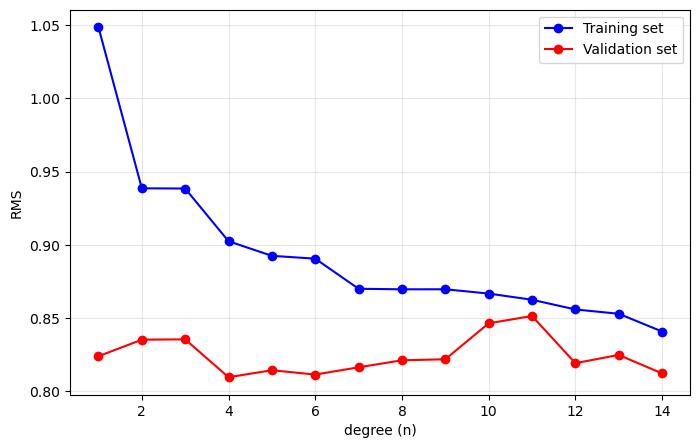

Best degree is n = 4 with a validation error of 0.8096


In [10]:
#help function

def geterror(X, y, model):
    pred = model.predict(X)
    return np.sqrt(np.mean((y - pred)**2))
def fitanderror(model):
    model.fit(X_train, y_train, dy_train)
    error_train = geterror(X_train, y_train, model)
    error_val   = geterror(X_val, y_val, model)
    return error_train, error_val


nrange = np.arange(1, 15)
etrain = []
etest = []
for n in nrange:
    model = PolynomialRegression(n)
    
    err_t, err_v = fitanderror(model)
    
    etrain.append(err_t)
    etest.append(err_v)
    print(f"Grado n={n:2d} | Train Error: {err_t:.3f} | Validation Error: {err_v:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(nrange, etrain, 'b-o', label='Training set')
plt.plot(nrange, etest, 'r-o', label='Validation set')
plt.xlabel('degree (n)')
plt.ylabel('RMS')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
best_n = nrange[np.argmin(etest)]
print(f"Best degree is n = {best_n} with a validation error of {min(etest):.4f}")

Miglior grado con 5-Fold CV: n = 2 (Validation RMS = 0.9394)


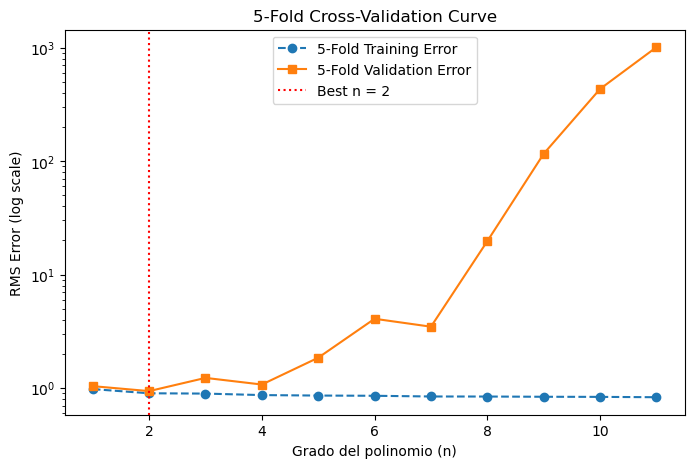

In [11]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
nrange = np.arange(1, 12)

cv_train_err = []
cv_val_err = []

for n in nrange:
    fold_train, fold_val = [], []
    for train_idx, val_idx in kf.split(x):
        model = PolynomialRegression(n)
        model.fit(x[train_idx], y[train_idx], dmu[train_idx])
        
        pred_train = model.predict(x[train_idx])
        pred_val = model.predict(x[val_idx])
        
        # Calcoliamo l'errore RMS sui fold di train e validation
        fold_train.append(np.sqrt(np.mean((y[train_idx] - pred_train)**2)))
        fold_val.append(np.sqrt(np.mean((y[val_idx] - pred_val)**2)))
        
    cv_train_err.append(np.mean(fold_train))
    cv_val_err.append(np.mean(fold_val))

best_n_cv = nrange[np.argmin(cv_val_err)]
print(f"Miglior grado con 5-Fold CV: n = {best_n_cv} (Validation RMS = {min(cv_val_err):.4f})")

plt.figure(figsize=(8, 5))
plt.plot(nrange, cv_train_err, 'o--', label='5-Fold Training Error')
plt.plot(nrange, cv_val_err, 's-', label='5-Fold Validation Error')
plt.axvline(best_n_cv, color='r', linestyle=':', label=f'Best n = {best_n_cv}')
plt.yscale('log')
plt.xlabel('Grado del polinomio (n)')
plt.ylabel('RMS Error (log scale)')
plt.title('5-Fold Cross-Validation Curve')
plt.legend()
plt.show()

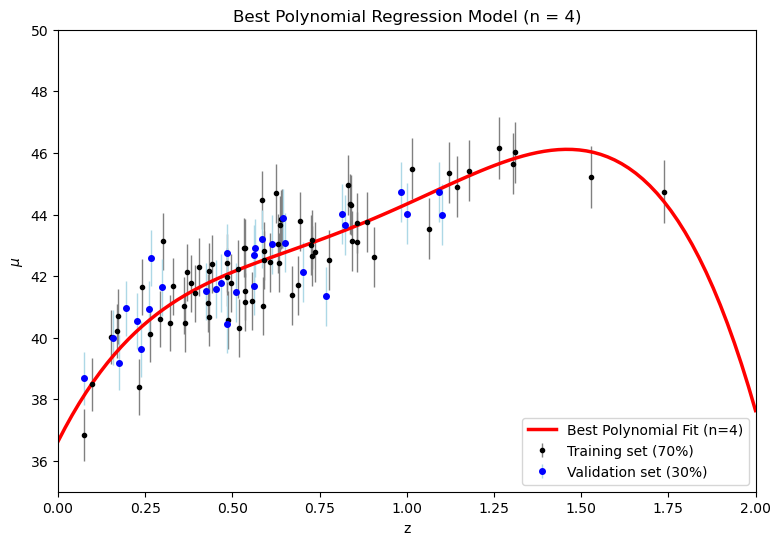

In [12]:
# Ri-fittiamo e plottiamo il modello migliore trovato (best_n = 4)
best_model = PolynomialRegression(best_n)
best_model.fit(X_train, y_train, dy_train)

z_grid = np.linspace(0, 2, 100)[:, np.newaxis]
mu_best = best_model.predict(z_grid)

plt.figure(figsize=(9, 6))
plt.errorbar(X_train.flatten(), y_train, dy_train, fmt='.k', ecolor='gray', lw=1, label='Training set (70%)')
plt.errorbar(X_val.flatten(), y_val, dy_val, fmt='ob', ecolor='lightblue', markersize=4, lw=1, label='Validation set (30%)')
plt.plot(z_grid, mu_best, 'r-', lw=2.5, label=f'Best Polynomial Fit (n={best_n})')

plt.xlabel("z")
plt.ylabel(r"$\mu$")
plt.xlim(0, 2)
plt.ylim(35, 50)
plt.title(f"Best Polynomial Regression Model (n = {best_n})")
plt.legend(loc='lower right')
plt.show()